In [ ]:
# Naive Bayes — IMDB Sentiment Classification

##### Bayes's Theorem

According to Wikipedia, **Bayes's theorem** describes the probability of an event,
based on prior knowledge of conditions that might be related to the event.
Mathematically:

$$P(A|B) = \\frac{P(B|A)\\cdot P(A)}{P(B)}$$

- P(A|B) — likelihood of A given B is true  
- P(B|A) — likelihood of B given A is true  
- P(A), P(B) — marginal probabilities  


**Example — rain / cloud:**

$$P(Rain|Cloud) = \\frac{P(Rain) \\times P(Cloud|Rain)}{P(Cloud)} = \\frac{0.1 \\times 0.5}{0.4} = 0.125$$

12.5% chance of rain — not too bad, let's have a picnic!


**Naïve Bayes:** assumes features are conditionally independent given the class.
Despite this (often wrong) assumption it works very well for text classification.


# Problem statement

IMDB sentiment classification using Naive Bayes classifiers — predict whether a movie review is **positive** or **negative** based on its content.


### Data processing using pandas library

In [1]:
# Import the required libraries
import string
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB, BernoulliNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
print('Imports OK')

Imports OK


### Loading the IMDB dataset

**Dataset:** `IMDB Dataset.csv` with two columns: `review` and `sentiment`.


In [2]:
data = pd.read_csv("C:/Users/Mahesh/Downloads/IMDB Dataset.csv")
data.head(8) # View the first 8 records of our dataset


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive
5,"Probably my all-time favorite movie, a story o...",positive
6,I sure would like to see a resurrection of a u...,positive
7,"This show was an amazing, fresh & innovative i...",negative


In [3]:
data.shape

(50000, 2)

### Exploratory Data Analysis

In [4]:
data['sentiment'].value_counts()


sentiment
positive    25000
negative    25000
Name: count, dtype: int64

In [5]:
# Review length feature
data['Length'] = data['review'].apply(len)
data.head()


,review,sentiment,Length
0,One of the other reviewers has mentioned that ...,positive,1761
1,A wonderful little production. <br /><br />The...,positive,998
2,I thought this was a wonderful way to spend ti...,positive,926
3,Basically there's a family where a little boy ...,negative,748
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive,1317


In [6]:
data['Length'].describe()

count    50000.000000
mean      1309.431020
std        989.728014
min         32.000000
25%        699.000000
50%        970.000000
75%       1590.250000
max      13704.000000
Name: Length, dtype: float64

In [7]:
# Longest review
data.loc[data['Length'] == data['Length'].max(), 'review'].values[0]


'Match 1: Tag Team Table Match Bubba Ray and Spike Dudley vs Eddie Guerrero and Chris Benoit Bubba Ray and Spike Dudley started things off with a Tag Team Table Match against Eddie Guerrero and Chris Benoit. According to the rules of the match, both opponents have to go through tables in order to get the win. Benoit and Guerrero heated up early on by taking turns hammering first Spike and then Bubba Ray. A German suplex by Benoit to Bubba took the wind out of the Dudley brother. Spike tried to help his brother, but the referee restrained him while Benoit and Guerrero ganged up on him in the corner. With Benoit stomping away on Bubba, Guerrero set up a table outside. Spike dashed into the ring and somersaulted over the top rope onto Guerrero on the outside! After recovering and taking care of Spike, Guerrero slipped a table into the ring and helped the Wolverine set it up. The tandem then set up for a double superplex from the middle rope which would have put Bubba through the table, bu

In [8]:
# Shortest review
data.loc[data['Length'] == data['Length'].min(), 'review'].values[0]


'Read the book, forget the movie!'

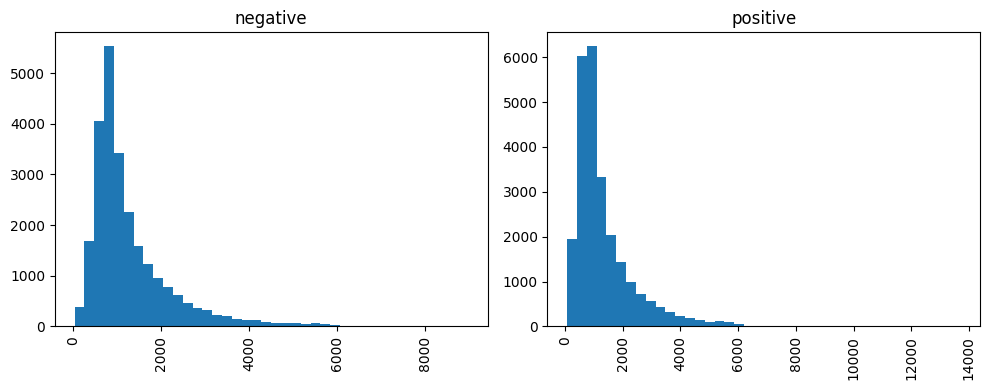

In [9]:
# Distribution of review lengths by sentiment
data.hist(column='Length', by='sentiment', bins=40, figsize=(10, 4))
plt.tight_layout()
plt.show()


### Label Encoding

**Label encoding:** `negative → 0` and `positive → 1` using `.map()`.


In [10]:
# Use .map() for sentiment encoding
# negative → 0 , positive → 1
data['Target'] = data['sentiment'].map({'negative': 0, 'positive': 1})
data[['sentiment', 'Target']].head(8)


,sentiment,Target
0,positive,1
1,positive,1
2,positive,1
3,negative,0
4,positive,1
5,positive,1
6,positive,1
7,negative,0


### Text Pre-processing

In [11]:
def remove_punct(text):
    """Remove punctuation and convert to lower case."""
    return ''.join(ch for ch in text if ch not in string.punctuation).lower()

data['text_clean'] = data['review'].apply(remove_punct)
data[['review', 'text_clean']].head(3)


,review,text_clean
0,One of the other reviewers has mentioned that ...,one of the other reviewers has mentioned that ...
1,A wonderful little production. <br /><br />The...,a wonderful little production br br the filmin...
2,I thought this was a wonderful way to spend ti...,i thought this was a wonderful way to spend ti...


In [12]:
data.head()

,review,sentiment,Length,Target,text_clean
0,One of the other reviewers has mentioned that ...,positive,1761,1,one of the other reviewers has mentioned that ...
1,A wonderful little production. <br /><br />The...,positive,998,1,a wonderful little production br br the filmin...
2,I thought this was a wonderful way to spend ti...,positive,926,1,i thought this was a wonderful way to spend ti...
3,Basically there's a family where a little boy ...,negative,748,0,basically theres a family where a little boy j...
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive,1317,1,petter matteis love in the time of money is a ...


### Splitting Train and Test Data

**Correct pipeline:** split the raw review text first, then fit the vectoriser on training text only, and `transform` the test text.


In [13]:
# Split raw text arrays first — no vectorising yet
X_text = data['text_clean'].values
y      = data['Target'].values.astype(int)

X_text_train, X_text_test, y_train, y_test = train_test_split(
    X_text, y, test_size=0.20, random_state=10
)

print('Train size:', len(X_text_train))
print('Test  size:', len(X_text_test))


Train size: 40000
Test  size: 10000


### Vectorisation — Bag of Words (CountVectorizer)

In [14]:
# FIX 3 cont.: fit CV on TRAINING text only
CV = CountVectorizer(stop_words='english')
X_train_cv = CV.fit_transform(X_text_train)  # fit + transform
X_test_cv  = CV.transform(X_text_test)        # transform only — same vocabulary

print('Vocabulary size:', len(CV.vocabulary_))
print('Train shape    :', X_train_cv.shape)
print('Test  shape    :', X_test_cv.shape)

Vocabulary size: 158445
Train shape    : (40000, 158445)
Test  shape    : (10000, 158445)


In [15]:
# FIX 4: get_feature_names() was removed in sklearn ≥ 1.0
# Use get_feature_names_out() instead
feature_names = CV.get_feature_names_out()
print('Total features:', len(feature_names))
print('Sample words  :', feature_names[:15])

Total features: 158445
Sample words  : ['00' '000' '0000000000001' '000001' '00000110' '0001' '00015' '001'
 '0010' '002' '00383042' '006' '0069' '007' '0079']


### Training a model — MultinomialNB


With messages represented as count vectors we can train the
**Multinomial Naive Bayes** classifier, a popular choice for text.


In [ ]:
NB = MultinomialNB()
NB.fit(X_train_cv, y_train)

In [ ]:
# Predict on test set (same CV vocabulary — no feature mismatch)
y_pred = NB.predict(X_test_cv)
y_pred

In [ ]:
accuracy = accuracy_score(y_test, y_pred) * 100
print(f'MultinomialNB Accuracy: {accuracy:.2f}%')

In [ ]:
print(classification_report(y_test, y_pred, target_names=['negative', 'positive']))


In [ ]:
cm = pd.DataFrame(
    confusion_matrix(y_test, y_pred),
    index=['Actual negative', 'Actual positive'],
    columns=['Predicted negative', 'Predicted positive'],
)
cm


### IMDBSentimentClassificationApplication


In [ ]:
def classify_review(review):
    """Return 'POSITIVE' or 'NEGATIVE' for any movie review string."""
    cleaned  = remove_punct(review)
    features = CV.transform([cleaned])
    pred     = NB.predict(features)[0]
    return 'POSITIVE' if pred == 1 else 'NEGATIVE'

# Demo on four sample reviews
samples = [
    'This movie was absolutely wonderful and the acting was excellent.',
    'I really enjoyed this film. It was entertaining and beautifully made.',
    'The movie was boring, poorly acted, and a complete waste of time.',
    'I did not like this film at all. The story was disappointing.',
]
for r in samples:
    print(f'  [{classify_review(r):>8}]  {r[:65]}')


## BAG OF WORDS

We cannot pass text directly to train our models in NLP — we must convert it into numbers. The simplest approach is the **Bag of Words** model: each document is represented as a vector of word counts.


In [ ]:
# Simple BoW example with CountVectorizer
documents = ['Dog bites man.', 'Man bites dog.', 'Dog eats meat.', 'Man eats food.']
processed = [doc.lower().replace('.', '') for doc in documents]

count_vect = CountVectorizer()
bow_rep    = count_vect.fit_transform(processed)

print('Corpus      :', processed)
print('Vocabulary  :', count_vect.vocabulary_)
print("BoW 'dog bites man'      :", bow_rep[0].toarray())
print("BoW 'man bites dog'      :", bow_rep[1].toarray())
temp = count_vect.transform(['dog and dog are friends'])
print("BoW 'dog and dog are friends':", temp.toarray())

## TF-IDF

In the BoW approach all words are treated equally. **TF-IDF** weights words
by how distinctive they are:

- **TF(t)** = (occurrences of t in doc) / (total terms in doc)  
- **IDF(t)** = log(total docs / docs containing t)  
- **TF-IDF(t)** = TF(t) × IDF(t)


### TF-IDF vectorisation + BernoulliNB


**FIX (toarray AttributeError):** `TfidfVectorizer.fit_transform()` returns
a *sparse* matrix. Calling `.toarray()` on it converts it to a dense ndarray.
If the cell is run a second time *X is already dense*, so `.toarray()` raises
`AttributeError: 'numpy.ndarray' object has no attribute 'toarray'`.

**Fix:** use `hasattr(X, 'toarray')` guard, or — better — perform the
conversion inline once and never overwrite X with the sparse form.


In [ ]:
# Reuse the same train/test text split for a fair comparison
tf = TfidfVectorizer(max_features=5000)

# fit on training text only, then transform both splits
X_train_tf = tf.fit_transform(X_text_train).toarray()  # dense, once
X_test_tf  = tf.transform(X_text_test).toarray()       # dense, once

# get_feature_names_out() replaces deprecated get_feature_names()
print('TF-IDF features:', len(tf.get_feature_names_out()))
print('Train shape     :', X_train_tf.shape)
print('Test  shape     :', X_test_tf.shape)


In [ ]:
## Creating training and testing split (already done above — reuse)
# X_train_tf, X_test_tf, y_train, y_test are ready
print('Shapes OK — no extra split needed')

In [ ]:
## Model creation — BernoulliNB
nb = BernoulliNB(alpha=0.01)
nb.fit(X_train_tf, y_train)
y_hat = nb.predict(X_test_tf)
y_hat

In [ ]:
print(classification_report(y_test, y_hat, target_names=['negative', 'positive']))


In [ ]:
pd.crosstab(y_test, y_hat, rownames=['Actual'], colnames=['Predicted'])


In [ ]:
## Accuracy
print(f'BernoulliNB Accuracy: {accuracy_score(y_test, y_hat)*100:.2f}%')

## Summary — Model Comparison

In [ ]:
acc_mnb = accuracy_score(y_test, y_pred)  * 100
acc_bnb = accuracy_score(y_test, y_hat)   * 100
print(f'CountVectorizer + MultinomialNB : {acc_mnb:.2f}%')
print(f'TF-IDF          + BernoulliNB   : {acc_bnb:.2f}%')


### Pros of Naive Bayes

- Fast and highly scalable
- Works for binary and multi-class classification
- Simple — depends on counting
- Great for text / sentiment classification
- Trains well on small datasets
- Handles missing data gracefully


### Cons of Naive Bayes

- Assumes all features are independent — cannot learn feature relationships
- Can learn individual feature importance but not inter-feature correlations


### Application of Naive Bayes

**Text classification / sentiment analysis:**
- Movie review sentiment classification
- News article classification (Sports, Technology …)
- Spam vs Ham classification

**Recommendation systems:**
- Combined with collaborative filtering to predict user preferences


### 3 Types of Naive Bayes in scikit-learn

| Variant | Best for |
|---|---|
| **GaussianNB** | Continuous features following a normal distribution |
| **MultinomialNB** | Discrete counts (e.g. word frequencies) |
| **BernoulliNB** | Binary features (word present / absent) |
